## For our initial plots

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

In [4]:
file_path = '/Users/filippa/Classes/LiberaRA/data/MODTRAN_Files/FV3_Modtran6_IO_v5_write_v2_scene_1.nc'
modtran_1 = xr.open_dataset(file_path)

In [5]:
solar_only = modtran_1["MODTRAN6_SPECTRAL_RADIANCE_TOA_WVN_CERES_TRMM_SOLARONLY_TOTAL"]


In [6]:
# wavelength and wavenumber are the same length of 2664, wavelength is in units of nm, wavenumber is in cm^-1
solar_only['wavelength'] = (1 / solar_only['wavenumber']) * 10 ** 7
solar_only = solar_only.sortby('wavelength', ascending=True)
wvl_solar = solar_only['wavelength'].values # 0.3 - 5um -> 300 - 5000nm
wvn_solar = solar_only['wavenumber'].values
L_nu_solar = solar_only.isel(ceres_trmm_viewing_zenith_angle=0,
                                        ceres_trmm_relative_azimuth_angle=0,
                                        ceres_trmm_solar_zenith_angle=0).values*1*10**4 #converting to Wm^-2sr^-1 / cm^-1
L_lambda_solar =( L_nu_solar * (1*10**7)) / (wvl_solar)**2 # in nm


sw_radiance = L_lambda_solar[(wvl_solar >= 300) & (wvl_solar <= 5000)]
sw_wvl = wvl_solar[(wvl_solar >= 300) & (wvl_solar <= 5000)]

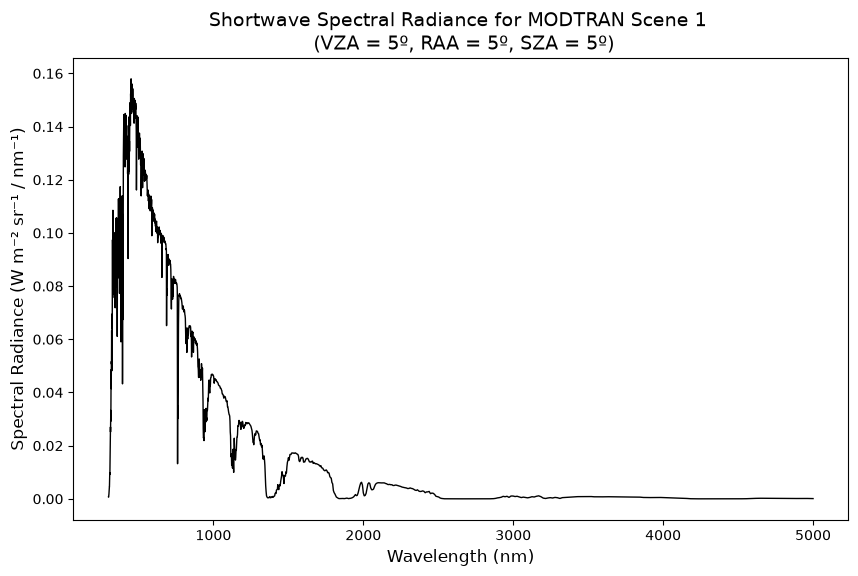

In [7]:
plt.figure(figsize = (10,6))
plt.plot(sw_wvl, sw_radiance, color = 'k', linewidth = 1)
plt.xlabel('Wavelength (nm)', fontsize=12)
plt.ylabel(f'Spectral Radiance (W m⁻² sr⁻¹ / nm⁻¹)', fontsize=12)
plt.title('Shortwave Spectral Radiance for MODTRAN Scene 1 \n (VZA = 5º, RAA = 5º, SZA = 5º)', fontsize=14)
plt.show()